In [141]:
# init scopetype & platform vars
SCOPETYPE = 'CWNANO'
PLATFORM = 'CWNANO' # cwnano alias for STM32F0_NANO

## Detect ChipWhisperer

In [142]:
import os
# modify this line to work for local folder structure
setupScript = "/home/"+os.getenv("USER")+"/Documents/chipwhisperer/jupyter/Setup_Scripts/Setup_Generic.ipynb"
%run "{setupScript}"
# %run "{setupScript}" # Running twice captures clock

INFO: Found ChipWhisperer😍
INFO: Found ChipWhisperer😍


## Run this

In [191]:
scope.default_setup()
target.flush()
plaintext = bytearray(range(16))

## Capture Function
- you have to change SS_VER in makefile to = SS_VER_1_1

In [183]:
def capture():
    scope.arm()
    target.simpleserial_write('p', plaintext)
    timeout = scope.capture()
    print("Capture timed out:", timeout)
    print("ADC samples:", len(scope.get_last_trace()))
    return scope.get_last_trace()

## Capture 2.0 Function
- - you have to change SS_VER in makefile to = SS_VER_2_1

In [184]:
def capture2():
    scope.arm()
    target.simpleserial_write('0x01', plaintext)
    timeout = scope.capture()
    print("Capture timed out:", timeout)
    print("ADC samples:", len(scope.get_last_trace()))
    return scope.get_last_trace()

## Capturing Multiple Traces

In [196]:
trace = []

def capture_traces(num):
    for i in range(num):
        scope.arm()
        target.simpleserial_write('0x01', plaintext)
        timeout = scope.capture()
    
        if timeout:
            print(f"Trace {i}: timed out")
            continue
    
        trace = scope.get_last_trace().copy()
        traces.append(trace)
    
        print(f"Captured trace {i}: {len(trace)} samples")

    print("Total successful traces:", len(traces))

## Plot Function 

In [186]:
import matplotlib.pylab as plt

def plot(trace):
#trace = scope.get_last_trace()

    plt.figure(figsize=(13, 8))
    plt.plot(trace)
    plt.title("ChipWhisperer Nano Power Trace")
    plt.xlabel("Sample Number")
    plt.ylabel("ADC Amplitude")
    plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.show()

In [197]:
def plots(trace):
    plt.figure(figsize=(12, 5))
    
    for i, trace in enumerate(traces):
        plt.plot(trace, alpha=0.5, label=f"Trace {i}")
    
    plt.title("CWNano AES Power Traces")
    plt.xlabel("Sample Number")
    plt.ylabel("ADC Amplitude")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

## ADDITION OPERATION: BUILD, UPLOAD, CAPTURE, PLOT

In [177]:
%%bash -s "$PLATFORM"
cd firmware/add
make clean

SS_VER set to SS_VER_2_1


/home/iceinmilk/Documents/chipwhisperer//firmware/mcu//hal/Makefile.hal:310: *** Invalid or empty PLATFORM: NONE. Known platforms: 
+-------------------------------------------------------+
| PLATFORM      | DESCRIPTION                           |
+=======================================================+
| MOST COMMON TARGETS                                   |
+=======================================================+
+-------------------------------------------------------+
| CWLITEARM     | CW-Lite Arm (Alias for CW308_STM32F3) |
+-------------------------------------------------------+
| CWNANO        | CW-Lite Nano (STM32F0_NANO)           |
+-------------------------------------------------------+
| CWHUSKY       | CW-Husky (Alias for CW312_SAM4S)      |
+-------------------------------------------------------+
+=======================================================+
| AVR/XMEGA Targets (8-Bit RISC)                        |
+=======================================================

CalledProcessError: Command 'b'cd firmware/add\nmake clean\n'' returned non-zero exit status 2.

In [178]:
%%bash -s "$PLATFORM"
cd firmware/add
make -j PLATFORM=$1

SS_VER set to SS_VER_2_1
SS_VER set to SS_VER_2_1
arm-none-eabi-gcc (Fedora 15.2.0-4.fc44) 15.2.0
Copyright (C) 2025 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWNANO 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
.
.
Compiling:
Compiling:
Compiling:
Compiling:
Compiling:
    simpleserial-add.c ...Assembling: /home/iceinmilk/Documents/chipwhisperer//firmware/mcu//hal//stm32f0/stm32f0_startup.S
    /home/iceinmilk/Documents/chipwhisperer//firmware/mcu//simpleserial/simpleserial.c ...arm-none-eabi-gcc -c -mcpu=cortex-m0 -I. -x assembler-with-cpp -mthumb -mfloat-abi=soft -ffunction-sections -DF_CPU=7372800 -Wa,-gstabs,-adhlns=objdir-CWNANO/stm32f0_startup.lst -I/home/iceinmilk/Documents/chipwhisperer//firmware/mcu//simpleserial/ -I/home/iceinmilk/Documents/chipwhisperer//firmware/mcu//hal/ -I/home/iceinmilk/Documen

/usr/lib/gcc/arm-none-eabi/15.2.0/../../../../arm-none-eabi/bin/ld: warning: simpleserial-add-CWNANO.elf has a LOAD segment with RWX permissions


Memory region         Used Size  Region Size  %age Used
             RAM:        1560 B         4 KB     38.09%
             ROM:        4944 B        32 KB     15.09%
Done!
.
.
.
.
.
Creating load file for Flash: simpleserial-add-CWNANO.hex
arm-none-eabi-objcopy -O ihex -R .eeprom -R .fuse -R .lock -R .signature simpleserial-add-CWNANO.elf simpleserial-add-CWNANO.hex
Creating load file for Flash: simpleserial-add-CWNANO.bin
Creating load file for EEPROM: simpleserial-add-CWNANO.eep
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature simpleserial-add-CWNANO.elf simpleserial-add-CWNANO.bin
arm-none-eabi-objcopy -j .eeprom --set-section-flags=.eeprom="alloc,load" \
--change-section-lma .eeprom=0 --no-change-warnings -O ihex simpleserial-add-CWNANO.elf simpleserial-add-CWNANO.eep || exit 0
Creating Extended Listing: simpleserial-add-CWNANO.lss
Creating Symbol Table: simpleserial-add-CWNANO.sym
arm-none-eabi-objdump -h -S -z simpleserial-add-CWNANO.elf > simpleserial

In [179]:
cmd = "/home/" + os.getenv("USER") + "/Documents/chipwhisperer/user/power_consumption_for_STM32F0/firmware/add/simpleserial-add-CWNANO.hex".format(PLATFORM)
cw.program_target(scope, prog, cmd)

Detected known STMF32: STM32F04xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 4943 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 4943 bytes


(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Capture timed out: True
ADC samples: 5000


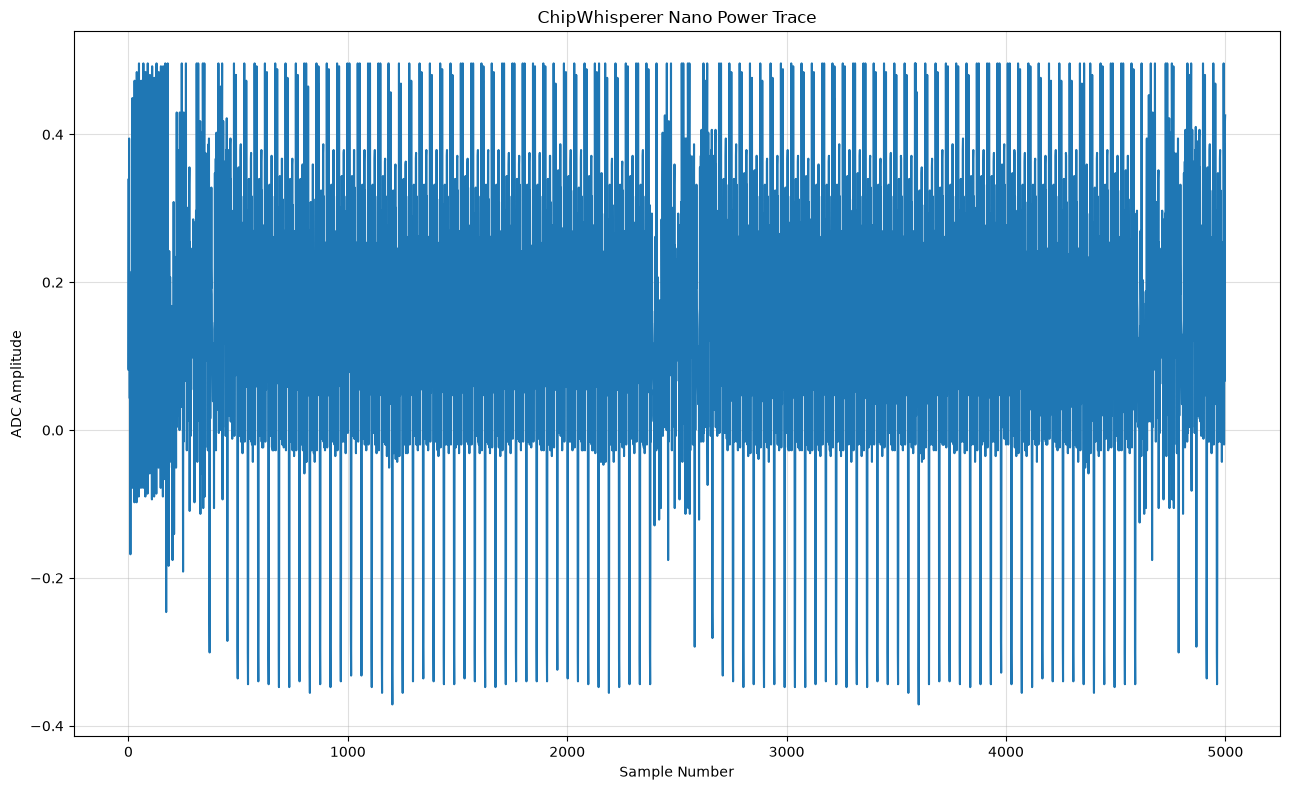

In [199]:
plot(capture())

(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Capture timed out: True
ADC samples: 5000


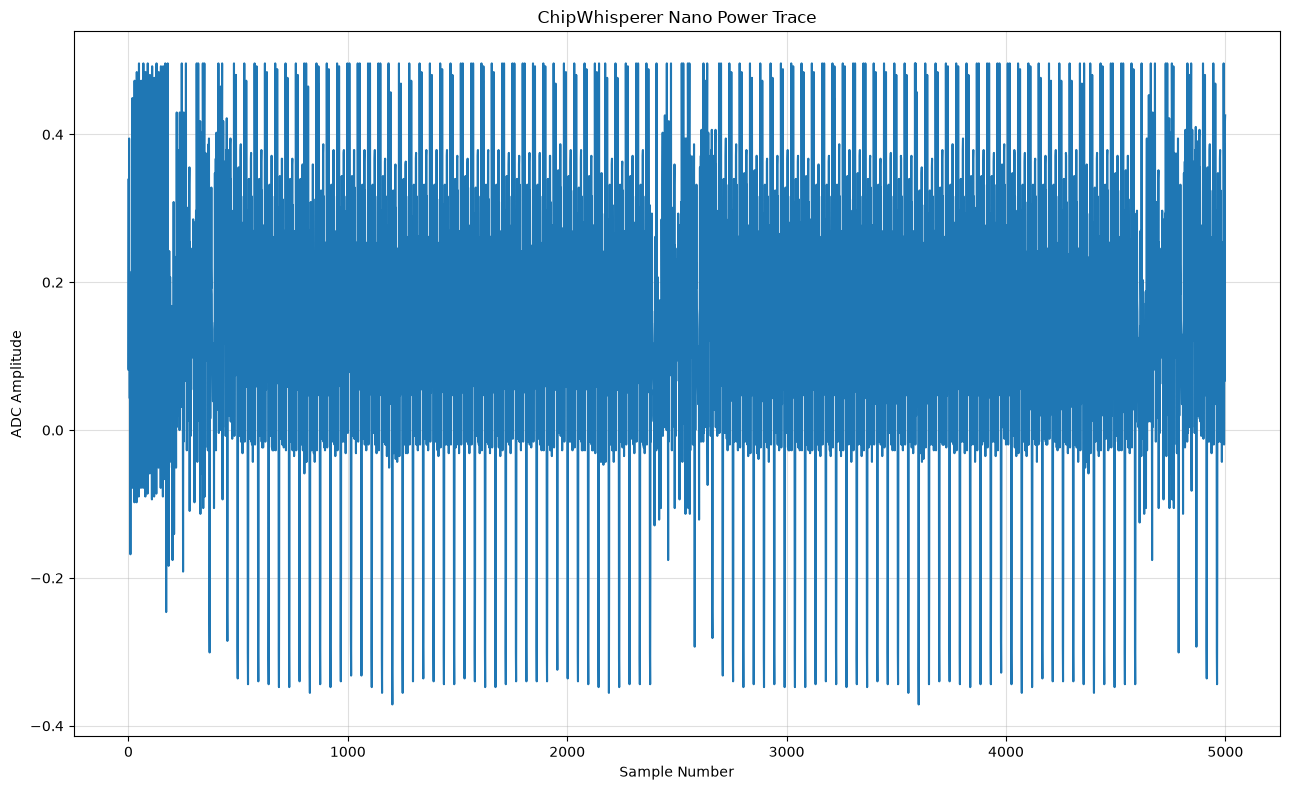

In [200]:
plot(capture2())

(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Trace 0: timed out


(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Trace 1: timed out


(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


...

(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Trace 8: timed out


(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Trace 9: timed out
Total successful traces: 0


/tmp/ipykernel_88985/97989254.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


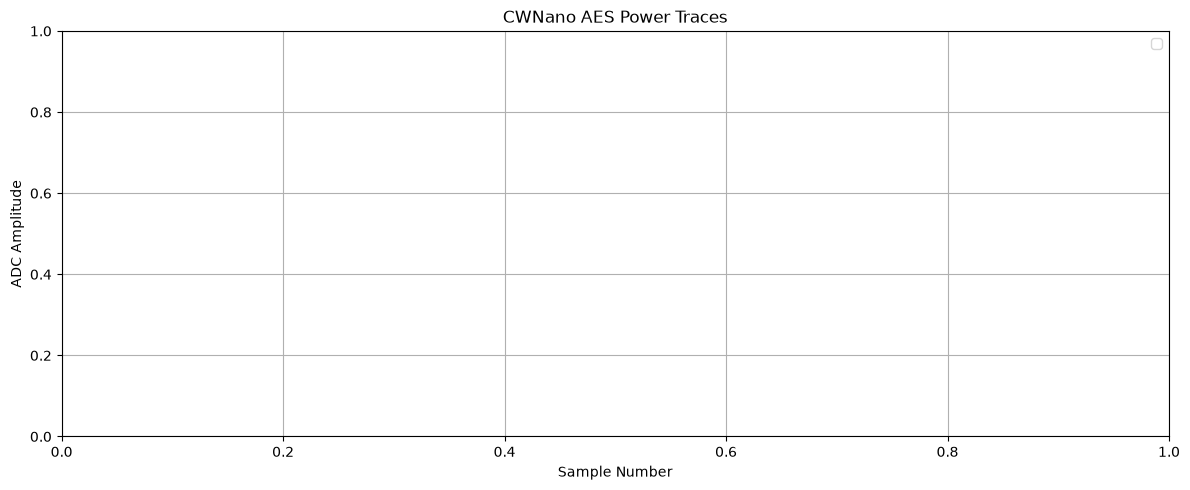

In [198]:
traces = []
num_traces = 10
capture_traces(num_traces)
plots(trace)

## SUBTRACT OPERATION: BUILD, UPLOAD, CAPTURE, PLOT

In [ ]:
%%bash -s "$PLATFORM"
cd firmware/subtract
make -j PLATFORM=$1

In [ ]:
cmd = "/home/" + os.getenv("USER") + "/Documents/chipwhisperer/user/power_consumption_for_STM32F0/firmware/subtract/simpleserial-subtract-CWNANO.hex".format(PLATFORM)
cw.program_target(scope, prog, cmd)

In [ ]:
plot(capture())

In [ ]:
traces = []
num_traces = 10
capture_traces(num_traces)

## MULTIPLY OPERATION: BUILD, UPLOAD, CAPTURE, PLOT

In [146]:
%%bash -s "$PLATFORM"
cd firmware/multiply
make -j PLATFORM=$1

SS_VER set to SS_VER_2_1
SS_VER set to SS_VER_2_1
arm-none-eabi-gcc (Fedora 15.2.0-4.fc44) 15.2.0
Copyright (C) 2025 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWNANO 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
.
.
Compiling:
Compiling:
Compiling:
Compiling:
Compiling:
    simpleserial-multiply.c ...Assembling: /home/iceinmilk/Documents/chipwhisperer//firmware/mcu//hal//stm32f0/stm32f0_startup.S
    /home/iceinmilk/Documents/chipwhisperer//firmware/mcu//simpleserial/simpleserial.c ...arm-none-eabi-gcc -c -mcpu=cortex-m0 -I. -x assembler-with-cpp -mthumb -mfloat-abi=soft -ffunction-sections -DF_CPU=7372800 -Wa,-gstabs,-adhlns=objdir-CWNANO/stm32f0_startup.lst -I/home/iceinmilk/Documents/chipwhisperer//firmware/mcu//simpleserial/ -I/home/iceinmilk/Documents/chipwhisperer//firmware/mcu//hal/ -I/home/iceinmilk/Do

/usr/lib/gcc/arm-none-eabi/15.2.0/../../../../arm-none-eabi/bin/ld: warning: simpleserial-multiply-CWNANO.elf has a LOAD segment with RWX permissions


Memory region         Used Size  Region Size  %age Used
             RAM:        1560 B         4 KB     38.09%
             ROM:        4808 B        32 KB     14.67%
Done!
.
.
.
.
.
Creating load file for Flash: simpleserial-multiply-CWNANO.hex
Creating load file for Flash: simpleserial-multiply-CWNANO.bin
arm-none-eabi-objcopy -O ihex -R .eeprom -R .fuse -R .lock -R .signature simpleserial-multiply-CWNANO.elf simpleserial-multiply-CWNANO.hex
Creating load file for EEPROM: simpleserial-multiply-CWNANO.eep
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature simpleserial-multiply-CWNANO.elf simpleserial-multiply-CWNANO.bin
Creating Extended Listing: simpleserial-multiply-CWNANO.lss
arm-none-eabi-objdump -h -S -z simpleserial-multiply-CWNANO.elf > simpleserial-multiply-CWNANO.lss
Creating Symbol Table: simpleserial-multiply-CWNANO.sym
arm-none-eabi-nm -n simpleserial-multiply-CWNANO.elf > simpleserial-multiply-CWNANO.sym
arm-none-eabi-objcopy -j .eeprom --set-sect

In [147]:
cmd = "/home/" + os.getenv("USER") + "/Documents/chipwhisperer/user/power_consumption_for_STM32F0/firmware/multiply/simpleserial-multiply-CWNANO.hex".format(PLATFORM)
cw.program_target(scope, prog, cmd)

(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Capture timed out: True
ADC samples: 5000


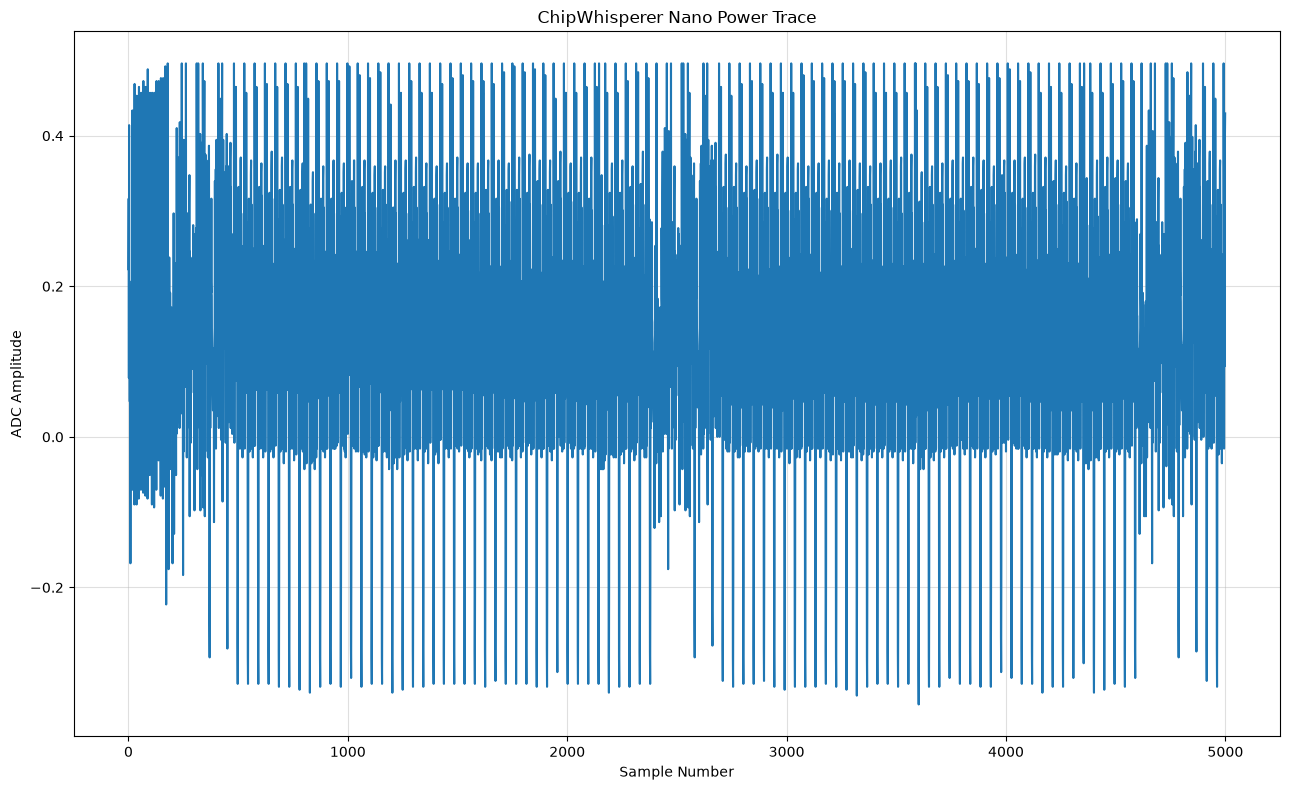

In [149]:
plot(capture())

## DIVIDE OPERATION: BUILD, UPLOAD, CAPTURE, PLOT

In [154]:
%%bash -s "$PLATFORM"
cd firmware/divide
make -j PLATFORM=$1

SS_VER set to SS_VER_2_1
SS_VER set to SS_VER_2_1
arm-none-eabi-gcc (Fedora 15.2.0-4.fc44) 15.2.0
Copyright (C) 2025 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWNANO 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
.
Compiling:
.
Compiling:
Compiling:
Compiling:
Compiling:
    simpleserial-divide.c ...Assembling: /home/iceinmilk/Documents/chipwhisperer//firmware/mcu//hal//stm32f0/stm32f0_startup.S
    /home/iceinmilk/Documents/chipwhisperer//firmware/mcu//simpleserial/simpleserial.c ...arm-none-eabi-gcc -c -mcpu=cortex-m0 -I. -x assembler-with-cpp -mthumb -mfloat-abi=soft -ffunction-sections -DF_CPU=7372800 -Wa,-gstabs,-adhlns=objdir-CWNANO/stm32f0_startup.lst -I/home/iceinmilk/Documents/chipwhisperer//firmware/mcu//simpleserial/ -I/home/iceinmilk/Documents/chipwhisperer//firmware/mcu//hal/ -I/home/iceinmilk/Docu

/usr/lib/gcc/arm-none-eabi/15.2.0/../../../../arm-none-eabi/bin/ld: warning: simpleserial-divide-CWNANO.elf has a LOAD segment with RWX permissions


Memory region         Used Size  Region Size  %age Used
             RAM:        1560 B         4 KB     38.09%
             ROM:        4808 B        32 KB     14.67%
Done!
.
.
.
.
.
Creating load file for Flash: simpleserial-divide-CWNANO.hex
arm-none-eabi-objcopy -O ihex -R .eeprom -R .fuse -R .lock -R .signature simpleserial-divide-CWNANO.elf simpleserial-divide-CWNANO.hex
Creating load file for EEPROM: simpleserial-divide-CWNANO.eep
Creating Extended Listing: simpleserial-divide-CWNANO.lss
Creating load file for Flash: simpleserial-divide-CWNANO.bin
arm-none-eabi-objcopy -j .eeprom --set-section-flags=.eeprom="alloc,load" \
--change-section-lma .eeprom=0 --no-change-warnings -O ihex simpleserial-divide-CWNANO.elf simpleserial-divide-CWNANO.eep || exit 0
Creating Symbol Table: simpleserial-divide-CWNANO.sym
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature simpleserial-divide-CWNANO.elf simpleserial-divide-CWNANO.bin
arm-none-eabi-objdump -h -S -z simpleser

In [155]:
cmd = "/home/" + os.getenv("USER") + "/Documents/chipwhisperer/user/power_consumption_for_STM32F0/firmware/divide/simpleserial-divide-CWNANO.hex".format(PLATFORM)
cw.program_target(scope, prog, cmd)

Detected known STMF32: STM32F04xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 4807 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 4807 bytes


(ChipWhisperer Scope WARNING|File cwnano.py:713) Timeout in cwnano capture()


Capture timed out: True
ADC samples: 5000


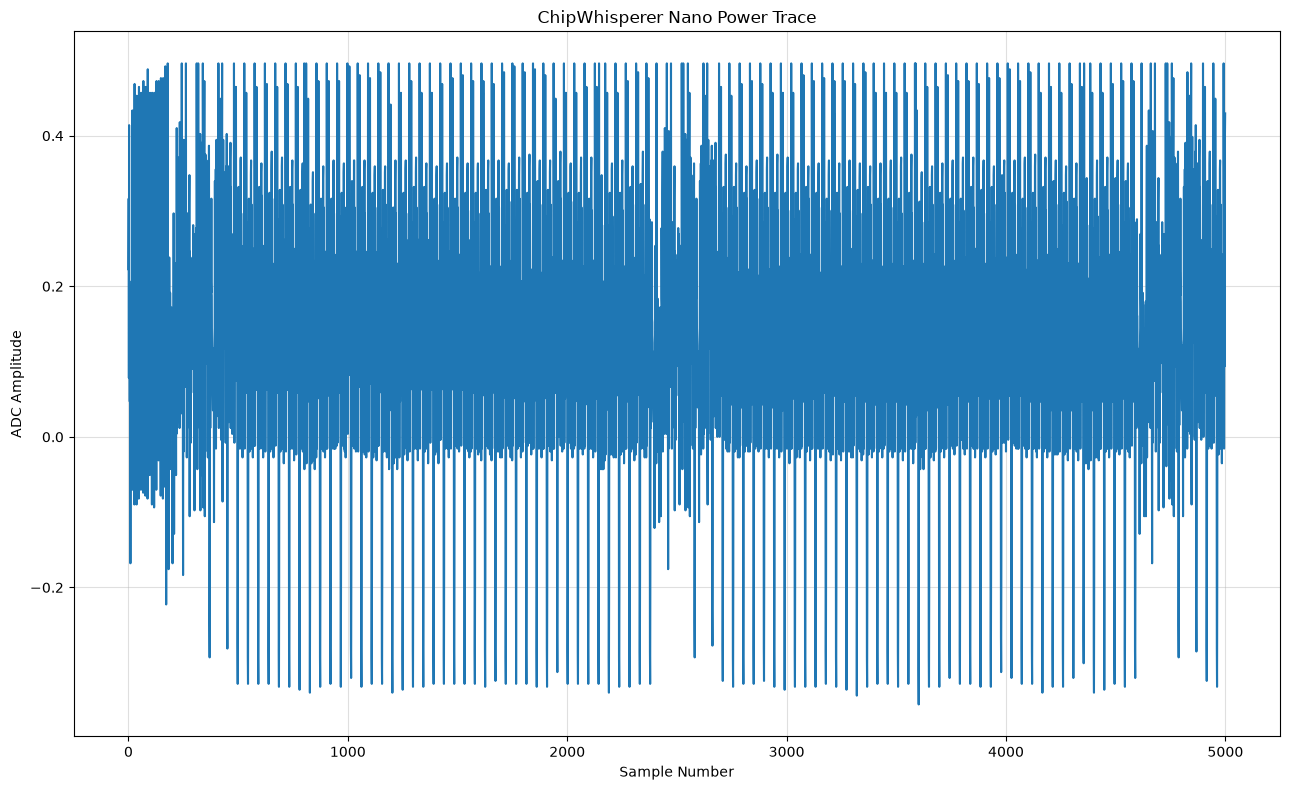

In [156]:
plot(capture())

## BITWISE AND OPERATION: BUILD, UPLOAD, CAPTURE, PLOT
### TO BE IMPLEMENTED

In [ ]:
%%bash -s "$PLATFORM"
cd firmware/and
make -j PLATFORM=$1

In [ ]:
cmd = "/home/" + os.getenv("USER") + "/Documents/chipwhisperer/user/power_consumption_for_STM32F0/firmware/AND/simpleserial-and-CWNANO.hex".format(PLATFORM)
cw.program_target(scope, prog, cmd)

In [ ]:
plot(capture())

# Disconnect
- to be run when done here

In [ ]:
target.dis()
scope.dis()